# Exploration 9: Projections and Least Squares

**Name:** Erica Zhang

Can you predict a car's fuel economy from its horsepower? In this exploration you'll build a small machine learning model that does, using nothing but linear algebra. First you'll fit curves to real data **by hand** and find out how quickly that gets hard. Then you'll see why finding the best curve is really a **projection**, and use that to compute it exactly.

We'll use [panchi](https://github.com/Gustavo-Galvao-e-Silva/panchi) and data on 32 cars from 1974.

**Every problem has three steps:**

- **Predict:** before running any code, write down what you think will happen. Predictions are graded on being *written first*, not on being right.
- **Run:** run the code. Until the final challenge, you only fill in the blanks; the rest of the code is written for you.
- **Explain:** compare what happened with your prediction and explain it in a sentence or two.

**How to complete this exploration**

1. Open the notebook in Google Colab and choose **File → Save a copy in Drive**, then work in that copy. (Skip this if the notebook was handed to you as your own copy, e.g. through Google Classroom.)
2. **Run the setup cell below once before beginning.** Then run the rest of the cells **from top to bottom**. Click a cell and press **Shift + Enter** to run it.
3. Wherever you see `___`, replace it with your answer and run the cell again.
4. Answer the written questions by double-clicking the *Your answer* cells and typing.
5. When you're done, run the **Export to PDF** cell at the very end and submit the PDF.

### Python in 60 seconds

- `x = 5` **stores** the value `5` under the name `x`. From then on, `x` means `5`.
- `print(x)` shows a value below the cell.
- Lines starting with `#` are **comments**. Python ignores them; they're notes for you.
- Python counts from **0**, not 1. The first row of a matrix is row `0`, the second is row `1`, and so on.
- `A @ B` **multiplies** matrices, or a matrix and a vector.
- `[1, 2]` is a **list** of numbers. We'll use lists to type vectors, like `[1, -1]` for $\begin{bmatrix}1\\-1\end{bmatrix}$.
- If a cell says *"This cell still has a ___ blank"*, there's still something to fill in!
- Errors are normal and nothing breaks: read the last line of the message, fix the cell, and run it again.

## ⚠️ RUN THIS SETUP CELL ONCE BEFORE BEGINNING THE EXPLORATION ⚠️

Click the ▶ button on the cell below. It takes about 30 seconds:

- A window will pop up asking for permission to access your **Google Drive**. Allow it, so the export cell at the end can find your saved notebook.
- Only run it **once**. Run it again only if Colab disconnects or you come back in a new session.

In [1]:
# @title ⚠️ RUN THIS SETUP CELL ONCE BEFORE BEGINNING THE EXPLORATION ⚠️
# @markdown Only change this if you **renamed** your notebook:
NOTEBOOK_NAME = "exploration_least_squares"  # @param {type:"string"}
NOTEBOOK_NAME = NOTEBOOK_NAME.strip().removesuffix(".ipynb")

import glob
import io
import json
import os
import tokenize
import uuid

# 1. Connect your Google Drive (a permission window will pop up)
from google.colab import drive

drive.mount("/content/drive")
MY_DRIVE = "/content/drive/MyDrive"

# 2. Install panchi
%pip install -q "panchi>=3.2"


# 3. Find your saved copy of this notebook in Drive, even if it's called "Copy of ..."
#    or has your name in front (the most recently saved one wins)
def find_notebook():
    found = []
    for folder in ["Colab Notebooks", "Classroom"]:
        found += glob.glob(f"{MY_DRIVE}/{folder}/**/*{NOTEBOOK_NAME}*.ipynb", recursive=True)
    return max(found, key=os.path.getmtime) if found else None


# 4. Friendly reminder instead of a confusing error when a cell still has a ___ blank
#    (IPython normally uses ___ as a name for an old output, so blanks wouldn't fail)
def _check_blanks(lines):
    try:
        tokens = tokenize.generate_tokens(io.StringIO("".join(lines)).readline)
        has_blank = any(t.type == tokenize.NAME and t.string == "___" for t in tokens)
    except Exception:
        return lines
    if has_blank:
        return ['print("This cell still has a ___ blank. '
                'Replace every ___ with your answer, then run it again.")\n']
    return lines


transformers = get_ipython().input_transformers_cleanup
transformers[:] = [t for t in transformers if getattr(t, "__name__", "") != "_check_blanks"]
transformers.append(_check_blanks)


# 5. The data: horsepower and miles per gallon of 32 cars (mtcars, Motor Trend, 1974)
import matplotlib.pyplot as plt
import panchi as pan
from IPython.display import HTML, display

hp_data = [110, 110, 93, 110, 175, 105, 245, 62, 95, 123, 123, 180, 180, 180, 205, 215, 230, 66, 52, 65, 97, 150, 150, 245, 175, 66, 91, 113, 264, 175, 335, 109]
mpg_data = [21.0, 21.0, 22.8, 21.4, 18.7, 18.1, 14.3, 24.4, 22.8, 19.2, 17.8, 16.4, 17.3, 15.2, 10.4, 10.4, 14.7, 32.4, 30.4, 33.9, 21.5, 15.5, 15.2, 13.3, 19.2, 27.3, 26.0, 30.4, 15.8, 19.7, 15.0, 21.4]
AVERAGE_HP = sum(hp_data) / len(hp_data)


def hp_to_x(hp):
    """x counts hundreds of horsepower above or below the average car."""
    return (hp - AVERAGE_HP) / 100


x_data = [hp_to_x(hp) for hp in hp_data]

# Every 4th car, ending with the strongest one, is held back as test data
_order = sorted(range(len(hp_data)), key=lambda i: hp_data[i])
_test = sorted(_order[3::4])
_train = [i for i in range(len(hp_data)) if i not in _test]
x_train = [x_data[i] for i in _train]
y_train = [mpg_data[i] for i in _train]
x_test = [x_data[i] for i in _test]
y_test = [mpg_data[i] for i in _test]


# 6. Helpers
def _numbers(coefficients):
    return coefficients.to_list() if isinstance(coefficients, pan.Vector) else list(coefficients)


def _value(coefficients, x):
    return sum(c * x**power for power, c in enumerate(_numbers(coefficients)))


def total_error(coefficients, xs=None, ys=None):
    """Add up the squared miss of every car."""
    xs = x_data if xs is None else xs
    ys = mpg_data if ys is None else ys
    return sum((y - _value(coefficients, x)) ** 2 for x, y in zip(xs, ys))


def typical_miss(coefficients, xs, ys):
    """How many mpg a prediction is typically off by."""
    return (total_error(coefficients, xs, ys) / len(xs)) ** 0.5


def predict(coefficients, hp):
    """Predict the mpg of a car with this horsepower."""
    return _value(coefficients, hp_to_x(hp))


def plot_fit(coefficients):
    """Draw the cars, your curve, and every car's miss."""
    fig, ax = plt.subplots(figsize=(7, 4), facecolor="#45423F")
    ax.set_facecolor("#45423F")
    hps = [40 + 3 * i for i in range(103)]
    for hp, x, y in zip(hp_data, x_data, mpg_data):
        ax.plot([hp, hp], [y, _value(coefficients, x)], color="#B8AFA8", lw=0.8, ls="--", zorder=1)
    ax.plot(hps, [predict(coefficients, hp) for hp in hps], color="#FFB592", lw=2.2, zorder=2)
    ax.scatter(hp_data, mpg_data, s=32, color="#F2EDE9", edgecolor="#45423F", zorder=3)
    ax.set_xlim(40, 345)
    ax.set_ylim(5, 37)
    ax.set_xlabel("Horsepower", color="#DDD6CE")
    ax.set_ylabel("Miles per gallon", color="#DDD6CE")
    ax.tick_params(colors="#DDD6CE")
    ax.grid(axis="y", color="#5A5652")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["bottom", "left"]].set_color("#8F8984")
    plt.show()
    print(f"Total squared error: {total_error(coefficients):.1f}")


_SLIDERS_HTML = """
<style>
  #BOX { background: #45423F; color: #F2EDE9; color-scheme: dark; font: 14px/1.4 system-ui, sans-serif; width: 700px; max-width: 100%; padding: 14px 16px; box-sizing: border-box; border-radius: 12px; }
  #BOX label { display: flex; gap: 12px; align-items: center; margin: 6px 0; }
  #BOX b { width: 14px; color: #FFB592; font-size: 16px; }
  #BOX input { flex: 1; accent-color: #FFB592; }
  #BOX output { width: 56px; text-align: right; font-variant-numeric: tabular-nums; }
  #BOX svg { width: 100%; display: block; }
  #BOX text { fill: #DDD6CE; font-size: 13px; }
  #BOX .error { font-size: 16px; font-weight: 600; font-variant-numeric: tabular-nums; margin: 4px 0 10px; }
</style>
<div id="BOX"></div>
<script>
(() => {
  const data = DATA;
  const box = document.getElementById(data.box);
  const px = hp => 60 + (hp - 40) * 620 / 305;
  const py = mpg => 350 - (mpg - 5) * 335 / 32;
  const value = (co, x) => co.reduce((sum, c, power) => sum + c * x ** power, 0);
  const toX = hp => (hp - data.average) / 100;

  let svg = '<svg viewBox="0 0 700 400">';
  svg += `<clipPath id="${data.box}c"><rect x="60" y="15" width="620" height="335"/></clipPath>`;
  for (let mpg = 5; mpg <= 35; mpg += 5) {
    svg += `<line x1="60" x2="680" y1="${py(mpg)}" y2="${py(mpg)}" stroke="#5A5652"/>`;
    svg += `<text x="52" y="${py(mpg) + 5}" text-anchor="end">${mpg}</text>`;
  }
  for (let hp = 50; hp <= 300; hp += 50) {
    svg += `<text x="${px(hp)}" y="370" text-anchor="middle">${hp}</text>`;
  }
  svg += '<path d="M60 15V350H680" fill="none" stroke="#8F8984"/>';
  svg += '<text x="370" y="394" text-anchor="middle">Horsepower</text>';
  svg += '<text transform="translate(16 182) rotate(-90)" text-anchor="middle">Miles per gallon</text>';
  svg += `<g clip-path="url(#${data.box}c)"><path class="misses" stroke="#B8AFA8" stroke-dasharray="4 3" fill="none"/>`;
  svg += '<polyline class="curve" fill="none" stroke="#FFB592" stroke-width="3" stroke-linejoin="round"/></g>';
  data.hp.forEach((hp, i) => {
    svg += `<circle cx="${px(hp)}" cy="${py(data.mpg[i])}" r="5" fill="#F2EDE9" stroke="#45423F" stroke-width="2">`;
    svg += `<title>${hp} hp, ${data.mpg[i]} mpg</title></circle>`;
  });
  const sliders = data.names.map((name, i) => `<label><b>${name}</b>
    <input type="range" min="${i ? -20 : 0}" max="${i ? 20 : 40}" step="0.05" value="${i ? 0 : 20}">
    <output></output></label>`).join("");
  box.innerHTML = `${svg}</svg><div class="error"></div>${sliders}`;

  const inputs = [...box.querySelectorAll("input")];
  const draw = () => {
    const co = inputs.map(input => Number(input.value));
    inputs.forEach(input => { input.nextElementSibling.textContent = Number(input.value).toFixed(2); });
    let misses = "", total = 0;
    data.hp.forEach((hp, i) => {
      const guess = value(co, toX(hp));
      total += (data.mpg[i] - guess) ** 2;
      misses += `M${px(hp)} ${py(data.mpg[i])}V${py(guess)}`;
    });
    box.querySelector(".misses").setAttribute("d", misses);
    const points = [];
    for (let hp = 40; hp <= 346; hp += 3) points.push(`${px(hp)},${py(value(co, toX(hp)))}`);
    box.querySelector(".curve").setAttribute("points", points.join(" "));
    box.querySelector(".error").textContent = `Total squared error: ${total.toFixed(1)}`;
  };
  inputs.forEach(input => input.addEventListener("input", draw));
  draw();
})();
</script>
"""


def explore_fit(degree):
    """Sliders for a polynomial of this degree. They run in the browser, so the plot follows the drag."""
    box = f"fit{uuid.uuid4().hex}"
    data = {"box": box, "names": ["c", "b", "a", "d"][: degree + 1], "hp": hp_data, "mpg": mpg_data, "average": AVERAGE_HP}
    display(HTML(_SLIDERS_HTML.replace("BOX", box).replace("DATA", json.dumps(data))))


def design_matrix(xs, degree):
    """The matrix with columns 1, x, x^2, ... up to the given degree."""
    return pan.Matrix([[float(x**power) for power in range(degree + 1)] for x in xs])


def to_plane_view():
    """Rewrite x, x^2 and mpg as 3D vectors, keeping every length and angle.

    The three vectors live in R^32, but three vectors only ever fill a 3D slice
    of it. Subtracting the averages sets the constant term c aside, and
    Gram-Schmidt gives directions to measure that slice with.
    """
    average_x2 = sum(x * x for x in x_data) / len(x_data)
    average_mpg = sum(mpg_data) / len(mpg_data)
    columns = [
        pan.Vector(x_data),
        pan.Vector([x * x - average_x2 for x in x_data]),
        pan.Vector([y - average_mpg for y in mpg_data]),
    ]
    directions = pan.gram_schmidt(columns)
    return [pan.Vector([float(pan.dot(d, v)) for d in directions]) for v in columns]


if find_notebook():
    print("Setup complete! You can start the exploration now.")
else:
    print("Setup complete, but your saved copy of this notebook wasn't found in Drive.")
    print("Choose File > Save a copy in Drive, then work in (and run setup in) that copy.")

Mounted at /content/drive
Setup complete, but your saved copy of this notebook wasn't found in Drive.
Choose File > Save a copy in Drive, then work in (and run setup in) that copy.


In [2]:
import panchi as pan
from panchi.visualizations import Animator3D

animator = Animator3D(figsize=(6, 6))

### Your data and tools

Instead of raw horsepower, we'll use $x$, the number of **hundreds of horsepower above the average car** (147 hp). So $x = 0$ is an average car, $x = 1$ is a 247 hp car, and $x = -0.5$ is a 97 hp car.

- Press play on a **Sliders** cell to get sliders for a curve. Each dashed line in the picture is one car's **miss**: how far the curve is from that car's real mpg.
- `plot_fit([...])` draws a curve from coefficients you type, and reports its **total squared error**: square every car's miss and add them up. Smaller is better.

Sliders don't show up in the PDF, so after using them, always type your numbers into the `plot_fit` cell below.

**Do not use `pan.solve()` until the exploration tells you to.**

## Problem 1. A line, by hand

We'll start with a line, $\text{mpg} = c + bx$.

**Predict:** do you expect more powerful cars to get more or fewer miles per gallon? So should $b$ be positive or negative? Why?

I think that more powerful cars will get more miles per gallon, because they are able to go farther due to additional power. b should be positive if powerful cars get more miles per gallon.

In [3]:
# @title Sliders { display-mode: "form" }
explore_fit(1)

Move the sliders until you can't improve the error. Then type your best $c$ and $b$ below.

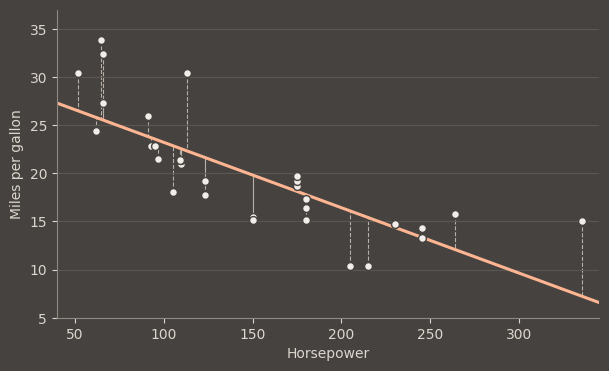

Total squared error: 447.7


In [4]:
my_line = [20.05, -6.80]  # [c, b]

plot_fit(my_line)

**Explain:** how did you find your line? Could you adjust $c$ and $b$ one at a time, or did changing one force you to redo the other? Does a line seem right for these cars?

When I changed one line, I had to redo the other to keep trying to find the least total squared error. I'm not sure if a straight line seems best, a curved line may be better.

## Problem 2. Curves, by hand

### (a) A quadratic

Now try $\text{mpg} = c + bx + ax^2$.

**Predict:** will the best quadratic beat your line by a lot, or only a little? Will it be harder to find?

I think the best quadratic will probably beat my line by quite a lot, however it will be harder to find since there are more sliders to slide.

In [5]:
# @title Sliders { display-mode: "form" }
explore_fit(2)

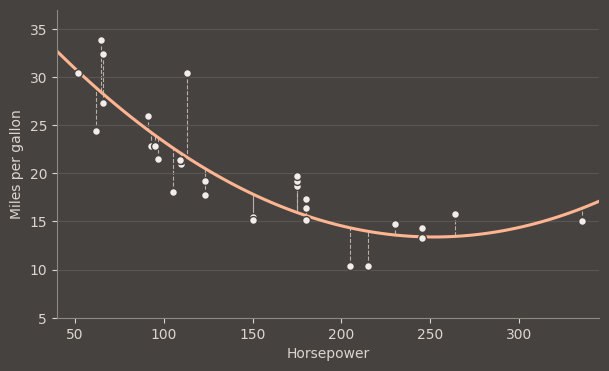

Total squared error: 274.7


In [6]:
my_quadratic = [18.15, -9.05, 4.30]  # [c, b, a]

plot_fit(my_quadratic)

**Explain:** what does $a$ do to the curve? When you changed $a$, what else did you have to change, and why?

A changes how curved the line is, which caused me to readjust b and c in order to turn the line to fit the data more.

### (b) A cubic

Now try $\text{mpg} = c + bx + ax^2 + dx^3$. Give yourself about 5 minutes, then stop.

**Predict:** how much lower will your error get than with the quadratic?

I think my error will get even lower, however it may be difficult to get it correct due to the fact that it is even more sliders to take care of.

In [7]:
# @title Sliders { display-mode: "form" }
explore_fit(3)

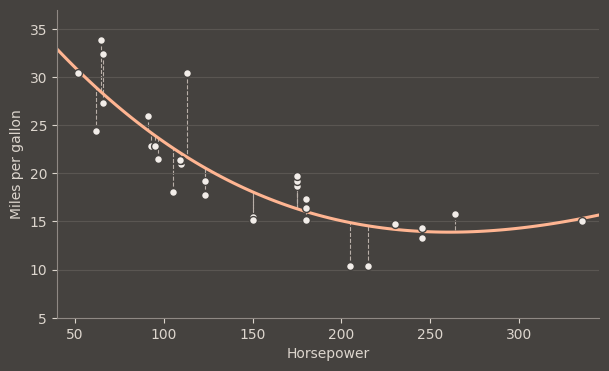

Total squared error: 272.9


In [8]:
my_cubic = [18.35, -8.40, 4.45, -0.45]  # [c, b, a, d]

plot_fit(my_cubic)

**Explain:** was the cubic worth the effort? Imagine doing this with 10 coefficients. Why do we need a better method than sliders?

Cubic was not worth the effort- there were too many sliders, and the line itself is not really cubic so it didn't change the error much from the quadratic. If there were 10 coefficients, it would be too many sliders to make an accurate prediction. We need a better method since for sliders, every time you change one thing you are forced to change the other, and you never really get the correct answer.

## Problem 3. Why this is a projection

Let's shrink the problem until we can see it: **3 cars** and a **line**. We picked these three because they're far from lying on a line.

| Car | Horsepower | $x$ | mpg |
|---|---|---|---|
| Toyota Corolla | 65 | $-0.82$ | 33.9 |
| Cadillac Fleetwood | 205 | $0.58$ | 10.4 |
| Maserati Bora | 335 | $1.88$ | 15.0 |

For the line $\text{mpg} = c + bx$ to pass through all three cars, we'd need

$$\begin{aligned} c - 0.82\,b &= 33.9 \\ c + 0.58\,b &= 10.4 \\ c + 1.88\,b &= 15.0 \end{aligned}$$

That's 3 equations with only 2 unknowns. As a matrix equation, it's $X\vec c = \vec y$:

$$\underbrace{\begin{bmatrix} 1 & -0.82 \\ 1 & 0.58 \\ 1 & 1.88 \end{bmatrix}}_{X} \underbrace{\begin{bmatrix} c \\ b \end{bmatrix}}_{\vec c} = \underbrace{\begin{bmatrix} 33.9 \\ 10.4 \\ 15.0 \end{bmatrix}}_{\vec y}$$

Each **row** of $X$ is one car. The first column is all 1s because $c$ is added for every car, and the second column holds the cars' $x$ values.

**A new way to look at the data.** In Problems 1 and 2, each car was a dot on a 2D graph. Now flip that around: put the 3 mpg values together, and $\vec y$ becomes **one point in $\mathbb{R}^3$**, with one axis for each car. Any line $[c, b]$ also gives one point in $\mathbb{R}^3$: its 3 predictions, $\vec p = X\vec c$.

### (a) No exact answer

**Predict:** does $X\vec c = \vec y$ have a solution? Think about what it would say about these three cars.

I think that it does not have a solution, but if it did it would mean that all the cars are probably the same model since they are all affected in the same way by horsepower and miles per gallon.

In [9]:
X = pan.Matrix([[1.0, -0.82], [1.0, 0.58], [1.0, 1.88]])
y = pan.Vector([33.9, 10.4, 15.0])

print(pan.solve(X, y).status)  # this one use of solve is allowed

inconsistent


So $\vec y$ is **not in the column space** of $X$. To see what the column space looks like, split $X\vec c$ into its columns:

$$\vec p = X\vec c = c\begin{bmatrix}1\\1\\1\end{bmatrix} + b\begin{bmatrix}-0.82\\0.58\\1.88\end{bmatrix}$$

Every line you could choose gives a combination of the same two vectors, and all those combinations make up a **plane** through the origin of $\mathbb{R}^3$. Every $\vec p$ lies on this plane, and $\vec y$ doesn't.

The entries of the **gap** $\vec y - \vec p$ are the line's 3 **misses**: how far the line is from each car's real mpg, like the dashed lines in Problem 1.

**Explain:** how does the length of the gap relate to the total squared error from Problems 1 and 2? (*Hint:* how do you compute the length of a vector?) Use that to explain why "finding the best line" is the same as "finding the point of the plane closest to $\vec y$".

By finding the best line, you are also trying to find the point of the plane closest to y, as both are trying to minimize the total squared error.

### (b) Hunt for the closest point

Pick a line $[c, b]$ and run the cell. The picture shows the plane **edge-on**, so it looks like a flat line: $\vec p$ always lies on it, $\vec y$ sits off it, and the dashed line is the gap between them. Below the picture you'll see each car's miss, the gap length, and the dot product of the gap with each column of $X$.

Try **at least 4** lines, trying to make the gap as short as you can. Run the cell once per guess, and write each guess down below. (Your line from Problem 1 is a fine first guess.)

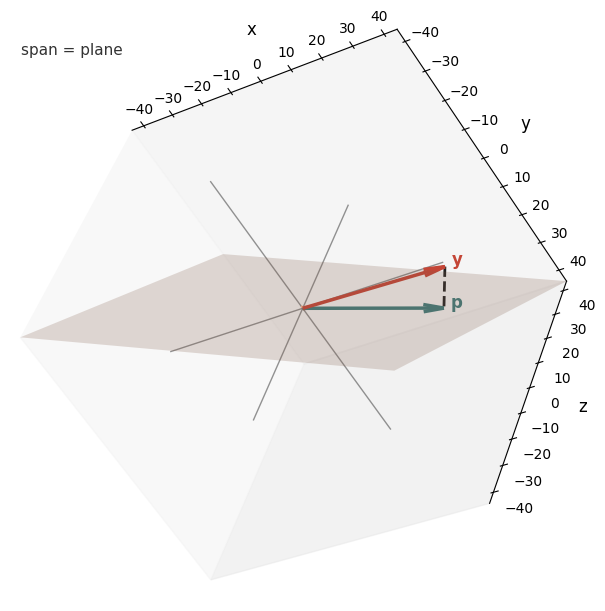

Misses (y - p): [4.58, -9.12, 4.58]
Gap length: 11.186
gap dot column 1: 0.04
gap dot column 2: -0.435


In [30]:
guess = pan.Vector([23.58, -7.0])  # [c, b]

p = X @ guess
gap = y - p

animator.plot_span(
    X.col_vectors,
    labels=["", ""],
    grid=False,
    vectors=[y, p],
    vector_labels=["y", "p"],
    gaps=[(y, p)],
    view="edge",
)

print("Misses (y - p):", [round(miss, 2) for miss in gap.to_list()])
print("Gap length:", round(gap.magnitude, 3))
print("gap dot column 1:", round(pan.dot(gap, X.col_vectors[0]), 3))
print("gap dot column 2:", round(pan.dot(gap, X.col_vectors[1]), 3))

**Your guesses:** list each $[c, b]$ with its gap length and its two dot products.
([20.05, -6.80], 12.682, 10.302, 4.446)
([22.05, -6.80], 11.473, 4.302, 1.166)
([24.05, -6.80], 11.243, -1.698, -2.114)
([23.58, -7.0], 11.186, 0.04, -0.435)
**Explain:** as your gap got shorter, what happened to the two dot products? What do you think they are at the very best $\vec p$? What does that say about the angle between the gap and the plane?

The two dot products get smaller and smaller. At the very best $\vec p$, i think they are 0. The angle is small.

### (c) The normal equations

At the closest point, the gap is **perpendicular to the plane**, so it is perpendicular to every column of $X$.

**Show by hand** that this condition can be written as $X^T(\vec y - X\vec c) = \vec 0$, and that this rearranges to the **normal equations**:

$$X^T X \vec c = X^T \vec y$$

*Hint:* what are the entries of $X^T\vec v$, for a vector $\vec v$?

When you multiply XT by v, then it becomes dot products of x and v. Since we want the dot products to be 0 so that they are perpendicular, then v has to be 0, so then $X^T(\vec y - X\vec c) = \vec 0$. Then you can distribute out Xt and move XTy over to the right to get the normal equation.
*(write your answer here)*

Now `pan.solve()` is allowed. Fill in the normal equations and solve them.

In [35]:
best = pan.solve(X, y).solution
print("Best [c, b]:", best)

p = X @ best
gap = y - p
print("Gap length:", round(gap.magnitude, 3))
print("gap dot column 1:", round(pan.dot(gap, X.col_vectors[0]), 6))
print("gap dot column 2:", round(pan.dot(gap, X.col_vectors[1]), 6))

animator.plot_span(
    X.col_vectors,
    labels=["", ""],
    grid=False,
    vectors=[y, p],
    vector_labels=["y", "p"],
    gaps=[(y, p)],
    view="edge",
)

Best [c, b]: None


TypeError: Cannot multiply Matrix by NoneType. Can only multiply by Vector or Matrix.

**Explain:** how close did your best guess get? Why does $X^TX\vec c = X^T\vec y$ have a solution when $X\vec c = \vec y$ doesn't?

*(write your answer here)*

## Problem 4. The best curve for all 32 cars

The same equations work for all 32 cars. Now $\vec y$ lives in $\mathbb{R}^{32}$, and each column of $X$ holds one power of $x$: `design_matrix(x_data, 2)` has columns $1, x, x^2$.

**Predict:** how will the exact answer compare with your hand-made quadratic? Write down which coefficient you think you were furthest off on.

*(write your prediction here **before** running the next cell)*

In [ ]:
X = design_matrix(x_data, ___)  # the degree of a quadratic
y = pan.Vector(mpg_data)

best_quadratic = pan.solve(___, ___).solution # fill in with what you are trying to solve for
print("Best [c, b, a]:", best_quadratic)
print("Your [c, b, a]:", my_quadratic)

plot_fit(best_quadratic)

**Explain:** how close were you? You searched with sliders for minutes. How many lines of code did this take?

*(write your answer here)*

### Seeing it in a plane

We can't draw $\mathbb{R}^{32}$, but we don't have to. The vectors $\vec x$, $\vec{x^2}$ and $\vec y$ are only three vectors, so they fit in a 3D slice of $\mathbb{R}^{32}$. `to_plane_view()` rewrites them in 3D and keeps every length and angle. It also subtracts the averages, which sets $c$ aside: $c$ only moves the whole curve up or down, and the plane shows the shape, which comes from $b$ and $a$.

**Predict:** in the picture, what should you see if $\vec p$ is really the projection of $\vec y$? How should the arrows $b\vec x$ and $a\vec{x^2}$ relate to $\vec p$?

*(write your prediction here **before** running the next cell)*

In [ ]:
c, b, a = best_quadratic.to_list()
x_3d, x2_3d, y_3d = to_plane_view()

b_part = x_3d * b
a_part = x2_3d * a
p_3d = b_part + a_part

animator.plot_span(
    [x_3d, x2_3d],
    labels=["", ""],
    grid=False,
    vectors=[y_3d, p_3d, b_part, a_part],
    vector_labels=["y", "p", "b x", "a x^2"],
    gaps=[(y_3d, p_3d), (b_part, p_3d), (a_part, p_3d)],
    view=(30, -90),
)

root_error = total_error(best_quadratic) ** 0.5
print("Gap length:", round((y_3d - p_3d).magnitude, 2))
print("Square root of total squared error:", round(root_error, 2))

**Explain:** the sliders moved $b$ and $a$. What were you moving in this picture? Why are the last two numbers printed above equal? (*Hint:* what is the length of the vector of all 32 misses?)

*(write your answer here)*

## Challenge: your mini machine learning model

A model is only useful if it works on cars it has **never seen**. We've split the cars for you: `x_train`, `y_train` hold 24 cars, and `x_test`, `y_test` hold the other 8. These 8 are every 4th car by horsepower, including the most powerful car of all.

This time there are no blanks: **write the code yourself.**

1. For **each degree from 1 to 5**, compute the best coefficients using **only the training cars**.
2. For each degree, compute `typical_miss(coefficients, x_train, y_train)` and `typical_miss(coefficients, x_test, y_test)`. These say how many mpg your predictions are typically off by.
3. Before you choose, draw your degree 1 and degree 5 models with `plot_fit(coefficients)`. Compare the two curves, especially on the right side of the plot.
4. Write down your results and **choose the degree you'd use** for your final model.
5. Use `predict(coefficients, hp)` to predict the mpg of a car with a horsepower of your choice.

*Hint:* use `design_matrix` as in Problem 4, with `x_train` in place of `x_data`, and `pan.Vector(y_train)` for $\vec y$. You can copy your cell and change the degree.

**Predict:** which degree will do best on the **training** cars? Which on the **test** cars?

*(write your prediction here **before** running the next cell)*

In [ ]:
# Fit your models here

In [ ]:
# Use your final model to make a prediction here

**Your results:** for each degree, list the training miss and the test miss.

*(write your answer here)*

**Explain:** which degree did you choose, and why? Why can a model with more coefficients do better on the training cars and far worse on the test cars? (*Hint:* look at where the test car with the most horsepower sits compared with the training cars.) What would you tell someone who only reports training error?

*(write your answer here)*

## Export to PDF

When you've finished everything above:

1. **Save** the notebook (**File → Save**, or Ctrl/Cmd + S). The PDF is made from the *saved* copy in your Drive.
2. Click the ▶ button on the cell below. The first time, it spends a few minutes installing the PDF tools before making your PDF.

Your PDF will download to your computer and also be saved in the main folder of your Google Drive (**My Drive**). The setup and export cells won't show up in the PDF.

In [ ]:
# @title Export to PDF
import shutil

from google.colab import files


def pdf_tools_ready():
    return shutil.which("xelatex") is not None and shutil.which("pandoc") is not None


# Install the PDF tools (LaTeX + pandoc) the first time this runs. It takes a few minutes.
if not pdf_tools_ready():
    print("Installing the PDF tools. This takes a few minutes, but only the first time...")
    !apt-get update -qq > /dev/null
    !DEBIAN_FRONTEND=noninteractive apt-get install -y -qq texlive-xetex texlive-fonts-recommended texlive-latex-extra texlive-plain-generic pandoc > /dev/null

NOTEBOOK = find_notebook()

if not pdf_tools_ready():
    print("Installing the PDF tools failed (see the messages above). Run this cell again.")
elif NOTEBOOK is None:
    print("Couldn't find your saved copy of this notebook in Drive.")
    print("Choose File > Save a copy in Drive, then work in that copy.")
else:
    # Copy the saved notebook out of Drive and convert it here. The PDF shows code and
    # outputs, hides the In [ ]: prompts, and leaves out the setup and export cells.
    LOCAL = f"/content/{NOTEBOOK_NAME}.ipynb"
    PDF = f"/content/{NOTEBOOK_NAME}.pdf"
    !rm -f "{PDF}"
    !cp "{NOTEBOOK}" "{LOCAL}"
    !jupyter nbconvert --to PDF "{LOCAL}" --log-level=ERROR --TemplateExporter.exclude_input_prompt=True --TemplateExporter.exclude_output_prompt=True --TagRemovePreprocessor.enabled=True --TagRemovePreprocessor.remove_cell_tags=remove_cell --TagRemovePreprocessor.remove_input_tags=remove_input

    if os.path.exists(PDF):
        !cp "{PDF}" "{MY_DRIVE}/"
        print("Done! Your PDF is in My Drive and is downloading now:", os.path.basename(PDF))
        files.download(PDF)
    else:
        print("Something went wrong making the PDF; see the messages above.")